In [3]:
import sys
from pathlib import Path

import matplotlib

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    # Run as a plain script by `main.py train`: write figures to disk, never open GUI windows.
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "bcb_monthly.csv"
ARTIFACTS = ROOT / "artifacts"
FIG_DIR = ARTIFACTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

THRESH = 0.50  # % m/m; target = 1 if IPCA(t+1) > THRESH

# Splits are on the forecast-origin month t (when the hedging decision is made).
TRAIN_START = "2003-01-01"
TRAIN_END = "2017-12-01"
VAL_END = "2020-12-01"  # test = everything after this

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)


def shade_splits(ax, end):
    ax.axvspan(pd.Timestamp(TRAIN_END), pd.Timestamp(VAL_END), color="orange", alpha=0.12, label="validation")
    ax.axvspan(pd.Timestamp(VAL_END), end, color="red", alpha=0.08, label="test")

## 1. Load the committed raw data

`data/raw/bcb_monthly.csv` was downloaded once from the Banco Central do Brasil SGS API by
`data/fetch_data.py`. Training reads only this file and never calls the API, so `main.py train`
is reproducible and doesn't fail when the API is down.

| column | SGS code | meaning |
|---|---|---|
| `ipca` | 433 | IPCA, monthly % change (**target source**) |
| `ipca15` | 7478 | IPCA-15, monthly % (mid-month preview of IPCA) |
| `selic` | 4390 | Selic accumulated in the month, % |
| `usdbrl` | 3698 | USD/BRL PTAX, monthly average |
| `icbr` | 27574 | IC-Br commodity price index (in BRL), level |
| `ibcbr` | 24364 | IBC-Br activity index, seasonally adjusted, level |

In [4]:
raw = pd.read_csv(RAW_PATH, parse_dates=["date"], index_col="date")
print(f"{raw.shape[0]} months x {raw.shape[1]} series, {raw.index.min():%Y-%m} to {raw.index.max():%Y-%m}")
raw.tail()

334 months x 6 series, 1999-01 to 2026-10


,ipca,ipca15,selic,usdbrl,icbr,ibcbr
date,,,,,,
2026-06-01,0.16,0.41,1.12,5.1276,442.88,110.15775
2026-07-01,0.07,0.06,1.22,5.1139,440.36,109.91611
2026-08-01,-0.32,-0.40,1.09,5.1532,456.24,NaN
2026-09-01,0.82,0.70,1.08,5.1447,462.94,NaN
2026-10-01,NaN,NaN,0.36,NaN,NaN,NaN


## 2. Data quality

In [5]:
expected = pd.date_range(raw.index.min(), raw.index.max(), freq="MS")
assert raw.index.is_unique and raw.index.equals(expected), "gaps or duplicates in the monthly index"


def missing_profile(frame):
    rows = {}
    for c in frame:
        s = frame[c]
        first, last = s.first_valid_index(), s.last_valid_index()
        rows[c] = {
            "n_missing": int(s.isna().sum()),
            "first_valid": first.date(),
            "last_valid": last.date(),
            "interior_gaps": int(s.loc[first:last].isna().sum()),
        }
    return pd.DataFrame(rows).T


missing_profile(raw)

,n_missing,first_valid,last_valid,interior_gaps
ipca,1,1999-01-01,2026-09-01,0
ipca15,17,2000-05-01,2026-09-01,0
selic,0,1999-01-01,2026-10-01,0
usdbrl,1,1999-01-01,2026-09-01,0
icbr,1,1999-01-01,2026-09-01,0
ibcbr,51,2003-01-01,2026-07-01,0


In [6]:
last_complete = raw["ipca"].last_valid_index()
dropped = raw.index[raw.index > last_complete]
print("Dropping incomplete months:", [f"{d:%Y-%m}" for d in dropped])
df = raw.loc[:last_complete].copy()
df.describe().T.round(2)

Dropping incomplete months: ['2026-10']


,count,mean,std,min,25%,50%,75%,max
ipca,333.0,0.50,0.39,-0.68,0.26,0.45,0.69,3.02
ipca15,317.0,0.49,0.40,-0.73,0.24,0.44,0.68,3.05
selic,333.0,1.00,0.42,0.13,0.76,0.99,1.22,3.33
usdbrl,333.0,3.18,1.35,1.50,2.03,2.85,4.12,6.10
icbr,333.0,177.21,122.91,43.05,93.84,124.72,198.68,482.57
ibcbr,283.0,94.12,10.13,69.18,88.66,96.43,100.93,111.14


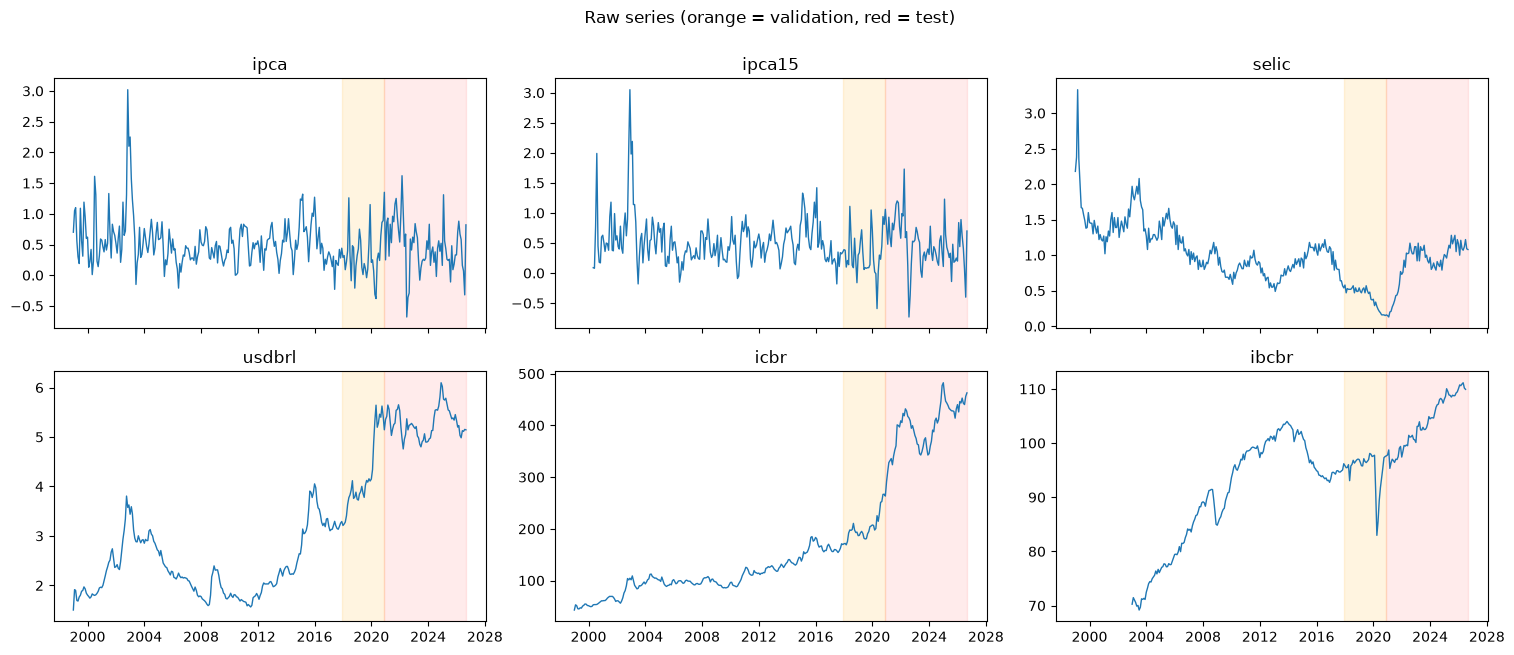

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True)
for ax, col in zip(axes.flat, df.columns):
    ax.plot(df.index, df[col], lw=1)
    ax.set_title(col)
    shade_splits(ax, df.index.max())
fig.suptitle("Raw series (orange = validation, red = test)", y=1.0)
fig.tight_layout()
save_fig(fig, "raw_series")

## 3. Target

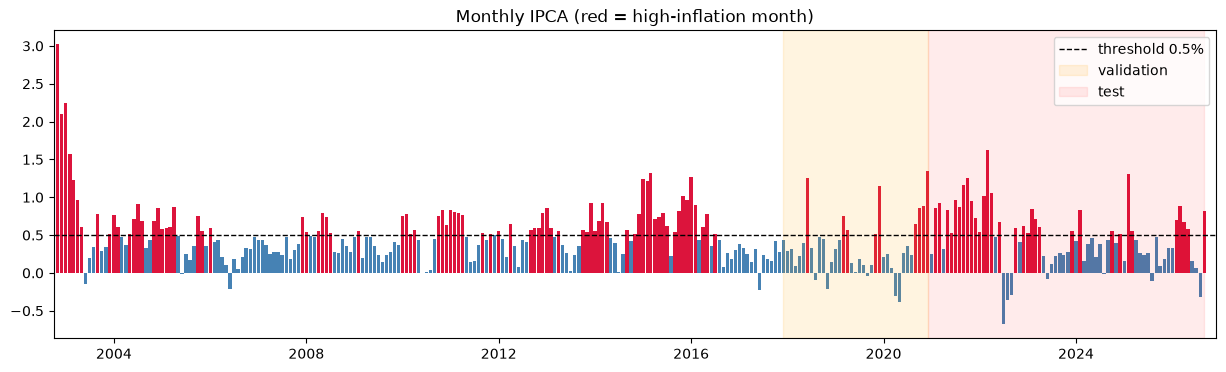

In [8]:
next_ipca = df["ipca"].shift(-1)  # IPCA of month t+1, aligned to the forecast origin t
target = (next_ipca > THRESH).astype(float).where(next_ipca.notna())

fig, ax = plt.subplots(figsize=(15, 4))
colors = np.where(df["ipca"] > THRESH, "crimson", "steelblue")
ax.bar(df.index, df["ipca"], width=25, color=colors)
ax.axhline(THRESH, color="black", ls="--", lw=1, label=f"threshold {THRESH}%")
shade_splits(ax, df.index.max())
ax.set_xlim(pd.Timestamp(TRAIN_START) - pd.DateOffset(months=3), df.index.max() + pd.DateOffset(months=3))
ax.set_title("Monthly IPCA (red = high-inflation month)")
ax.legend(loc="upper right")
save_fig(fig, "target_timeline")

In [9]:
def split_of(idx):
    return pd.Series(np.select([idx <= TRAIN_END, idx <= VAL_END], ["train", "val"], "test"), index=idx)


t = target.loc[TRAIN_START:].dropna()
pd.DataFrame({
    "n": t.groupby(split_of(t.index)).size(),
    "n_high": t.groupby(split_of(t.index)).sum().astype(int),
    "base_rate": t.groupby(split_of(t.index)).mean().round(3),
}).loc[["train", "val", "test"]]

,n,n_high,base_rate
train,180,76,0.422
val,36,9,0.250
test,68,32,0.471


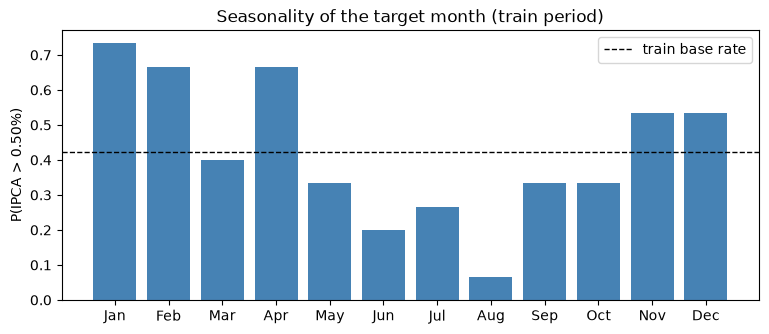

,p_high
date,
1,0.73
2,0.67
3,0.40
4,0.67
5,0.33
6,0.20
7,0.27
8,0.07
9,0.33


In [10]:
train_mask = (target.index >= TRAIN_START) & (target.index <= TRAIN_END)
target_month = (target.index + pd.DateOffset(months=1)).month  # calendar month being predicted

season = target[train_mask].groupby(target_month[train_mask]).mean()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(season.index, season.values, color="steelblue")
ax.axhline(target[train_mask].mean(), color="black", ls="--", lw=1, label="train base rate")
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("P(IPCA > 0.50%)")
ax.set_title("Seasonality of the target month (train period)")
ax.legend()
save_fig(fig, "target_seasonality")
season.round(2).to_frame("p_high")

In [11]:
# Persistence: how often is the next month high, given whether the last *published* month was high?
last_known_high = (df["ipca"].shift(1) > THRESH).astype(int)
pd.crosstab(
    last_known_high[train_mask].rename("last published IPCA (t-1) high"),
    target[train_mask].rename("target: IPCA(t+1) high"),
    normalize="index",
).round(2)

target: IPCA(t+1) high,0.0,1.0
last published IPCA (t-1) high,,
0,0.73,0.27
1,0.38,0.62


## 4. Information set: what is actually known at the end of month *t*?

| series | released | usable at origin *t* |
|---|---|---|
| IPCA | ~10th of following month | **t−1** |
| IPCA-15 | ~25th of same month | **t** |
| Selic, USD/BRL | market data, real time | **t** |
| IC-Br | early following month | **t−1** |
| IBC-Br | ~6 weeks after month end | **t−2** |

## 5. Feature engineering

The feature set is deliberately small: **one feature per economic idea**, each built from data
that is published by the decision date.

In [12]:
def compound(pct, window):
    """Compounded % change over `window` months from a series of monthly % changes."""
    return ((1 + pct / 100).rolling(window).apply(np.prod, raw=True) - 1) * 100


def pct_change(s, k):
    return (s / s.shift(k) - 1) * 100


def build_features(df):
    f = pd.DataFrame(index=df.index)
    ipca_12m = compound(df["ipca"].shift(1), 12)  # 12m inflation up to the last published month (t-1)

    f["ipca15"] = df["ipca15"]                                     # latest inflation reading (t)
    f["ipca_12m"] = ipca_12m                                       # inflation regime (t-1)
    f["usdbrl_chg_3m"] = pct_change(df["usdbrl"], 3)               # FX pass-through (t)
    f["icbr_chg_3m"] = pct_change(df["icbr"].shift(1), 3)          # commodity prices (t-1)
    f["real_rate_ex_post"] = compound(df["selic"], 12) - ipca_12m  # monetary policy (t)
    f["ibcbr_growth_3m"] = pct_change(df["ibcbr"].shift(2), 3)     # demand pressure (t-2)

    # Seasonality of the month being predicted (t+1); January is the reference category
    month = pd.Series((df.index + pd.DateOffset(months=1)).month, index=df.index)
    f = f.join(pd.get_dummies(month, prefix="tm", dtype=float).drop(columns="tm_1"))
    return f


features = build_features(df)
NUMERIC = [c for c in features if not c.startswith("tm_")]
SEASONAL = [c for c in features if c.startswith("tm_")]
print(f"{len(NUMERIC)} numeric + {len(SEASONAL)} seasonal dummies = {features.shape[1]} features")

6 numeric + 11 seasonal dummies = 17 features


| feature | idea | known at | why it should matter |
|---|---|---|---|
| `ipca15` | latest inflation reading | t | Mid-month preview of IPCA covering about half of month *t*. Inflation is persistent, so this is the strongest timely signal. |
| `ipca_12m` | inflation regime | t−1 | IPCA compounded over 12 months. High-inflation periods produce more months above 0.50%. |
| `usdbrl_chg_3m` | FX pass-through | t | A weaker real makes imports more expensive, reaching consumer prices within a few months. |
| `icbr_chg_3m` | commodity prices | t−1 | Commodity price rises (in BRL) feed into food and fuel prices. |
| `real_rate_ex_post` | monetary policy | t | Selic over the last 12m minus inflation over the last 12m. A high real rate should cool inflation. |
| `ibcbr_growth_3m` | demand pressure | t−2 | A faster-growing economy means more demand-driven price pressure. |
| `tm_2` … `tm_12` | seasonality | calendar | Dummies for the month being predicted. The pattern is irregular (high in February from school fees, low in August), so dummies fit it better than a smooth curve. |

FX, commodities and activity enter as **% changes, not levels**. Their levels trend over time,
so the model would mostly learn "what year it is", and test-period values would fall outside the
training range.

In [13]:
data = features.assign(target=target, next_ipca=next_ipca).loc[TRAIN_START:]
nan_rows = data.index[data.isna().any(axis=1)]
model_df = data.dropna()

# Rows may only be lost at the edges of the sample, never in the middle.
assert model_df.index.equals(data.loc[model_df.index.min():model_df.index.max()].index)

print(f"Dropped {len(nan_rows)} rows with NaNs: {[f'{d:%Y-%m}' for d in nan_rows]}")
print(f"Modelling sample: {model_df.index.min():%Y-%m} to {model_df.index.max():%Y-%m}, {len(model_df)} origins")
data[data.isna().any(axis=1)].isna().sum().loc[lambda s: s > 0].to_frame("NaNs in dropped rows")

Dropped 6 rows with NaNs: ['2003-01', '2003-02', '2003-03', '2003-04', '2003-05', '2026-09']
Modelling sample: 2003-06 to 2026-08, 279 origins


,NaNs in dropped rows
ibcbr_growth_3m,5
target,1
next_ipca,1


## 6. Split, then feature EDA on the training set

In [14]:
split = split_of(model_df.index)
model_df = model_df.assign(split=split)

summary = model_df.groupby("split").agg(
    start=("target", lambda s: f"{s.index.min():%Y-%m}"),
    end=("target", lambda s: f"{s.index.max():%Y-%m}"),
    n=("target", "size"),
    base_rate=("target", "mean"),
).loc[["train", "val", "test"]].round(3)
summary

,start,end,n,base_rate
split,,,,
train,2003-06,2017-12,175,0.411
val,2018-01,2020-12,36,0.250
test,2021-01,2026-08,68,0.471


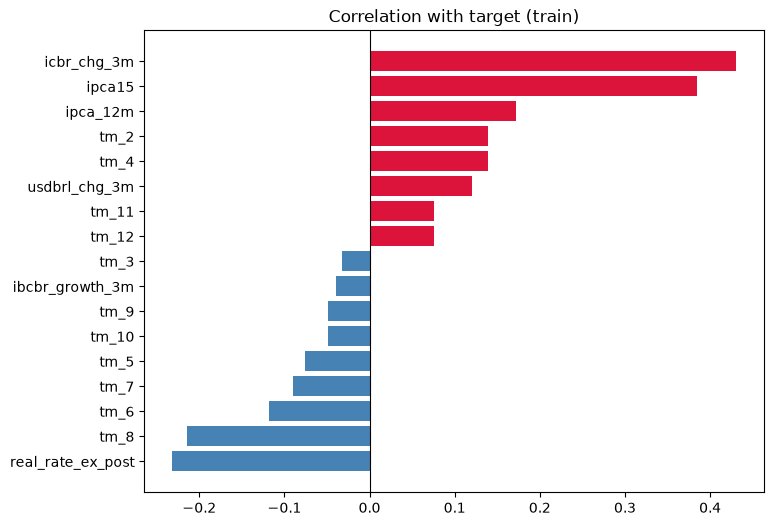

In [15]:
train = model_df[model_df["split"] == "train"]

# How strongly does each feature separate the classes? (point-biserial = Pearson with a 0/1 target)
corr_with_target = train[NUMERIC + SEASONAL].corrwith(train["target"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(corr_with_target.index, corr_with_target.values,
        color=np.where(corr_with_target > 0, "crimson", "steelblue"))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Correlation with target (train)")
save_fig(fig, "feature_target_corr")

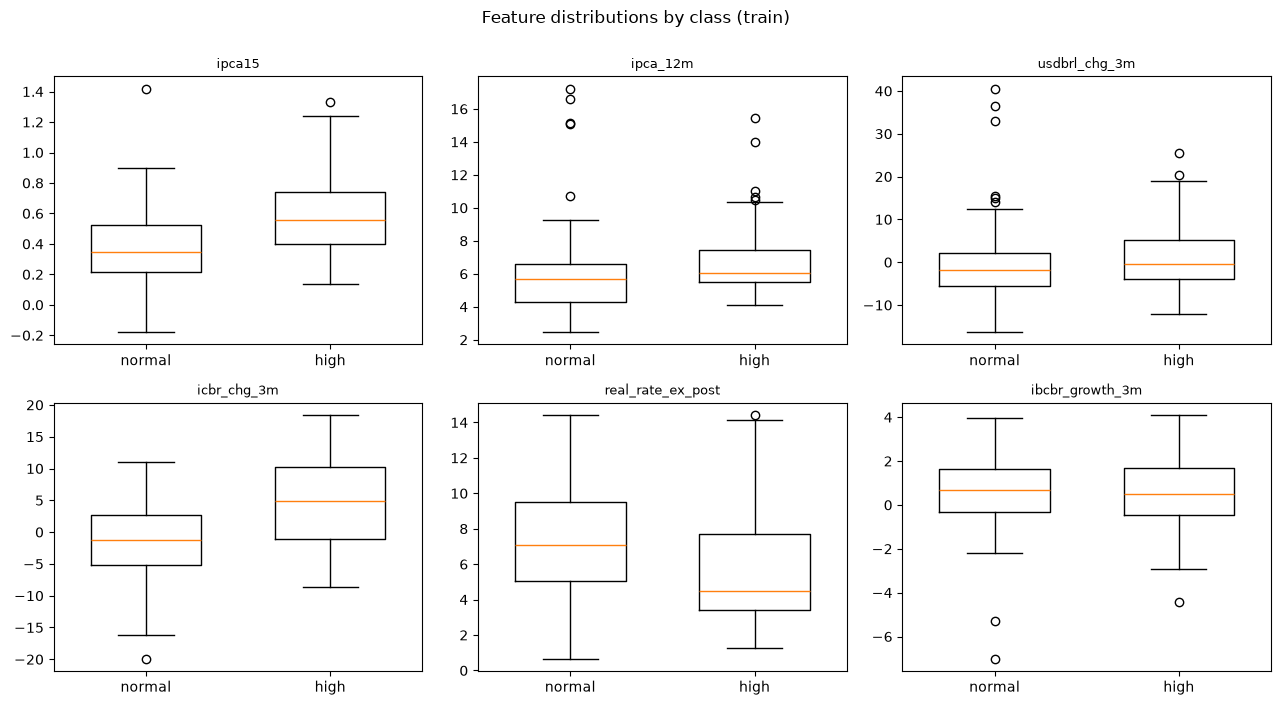

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, NUMERIC):
    ax.boxplot([train.loc[train.target == 0, col], train.loc[train.target == 1, col]],
               tick_labels=["normal", "high"], widths=0.6)
    ax.set_title(col, fontsize=9)
for ax in axes.flat[len(NUMERIC):]:
    ax.axis("off")
fig.suptitle("Feature distributions by class (train)", y=1.0)
fig.tight_layout()
save_fig(fig, "feature_by_class")

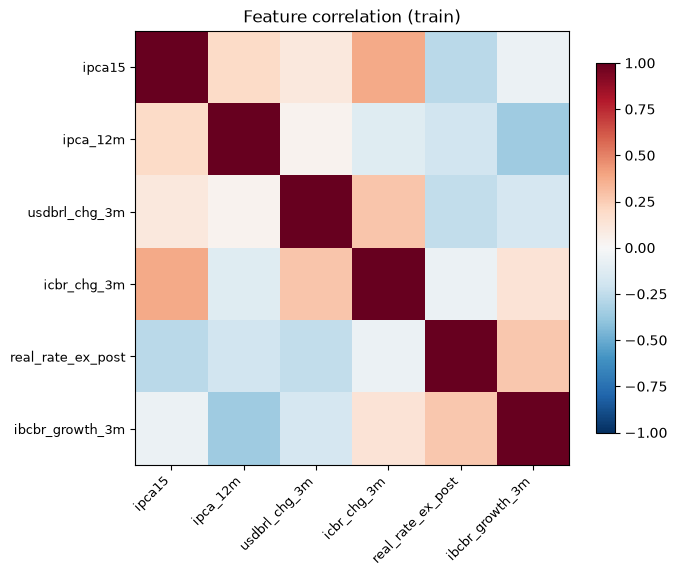

,ipca15,ipca_12m,usdbrl_chg_3m,icbr_chg_3m,real_rate_ex_post,ibcbr_growth_3m
ipca15,1.00,0.19,0.11,0.38,-0.27,-0.06
ipca_12m,0.19,1.00,0.04,-0.12,-0.19,-0.36
usdbrl_chg_3m,0.11,0.04,1.00,0.28,-0.24,-0.17
icbr_chg_3m,0.38,-0.12,0.28,1.00,-0.06,0.13
real_rate_ex_post,-0.27,-0.19,-0.24,-0.06,1.00,0.27
ibcbr_growth_3m,-0.06,-0.36,-0.17,0.13,0.27,1.00


In [17]:
corr = train[NUMERIC].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(NUMERIC)), NUMERIC, fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Feature correlation (train)")
save_fig(fig, "feature_corr_matrix")

corr.round(2)

In [18]:
shift = model_df.groupby("split")[NUMERIC].agg(["mean", "std"]).T.unstack()[["train", "val", "test"]]
shift.round(2)

split             train         val        test      
                   mean   std  mean   std  mean   std
ipca15             0.47  0.28  0.33  0.37  0.48  0.40
ipca_12m           6.31  2.51  3.49  0.84  6.09  2.47
usdbrl_chg_3m      0.36  8.38  4.62  8.31 -0.08  5.27
icbr_chg_3m        1.08  6.85  4.24  7.20  2.61  7.22
real_rate_ex_post  6.77  3.53  2.54  1.72  4.32  5.95
ibcbr_growth_3m    0.51  1.62  0.17  4.62  0.67  1.27

In [19]:
# Persist the engineered dataset (with its split) for the modelling stage and the dashboard.
model_df.to_csv(ARTIFACTS / "features.csv")
print(f"Saved {ARTIFACTS / 'features.csv'}: {model_df.shape}")

Saved /Users/marcelafunabashi/dai/daiist-assignment-1/artifacts/features.csv: (279, 20)


In [20]:
import json

import joblib
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, log_loss, roc_auc_score
from sklearn.preprocessing import StandardScaler

MODEL_DIR = ARTIFACTS / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = NUMERIC + SEASONAL  # column order of the model matrix
SPLITS = ["train", "val", "test"]
parts = {s: model_df[model_df["split"] == s] for s in SPLITS}

scaler = StandardScaler().fit(parts["train"][NUMERIC])


def to_matrix(frame):
    return np.hstack([scaler.transform(frame[NUMERIC]), frame[SEASONAL].to_numpy()])


X = {s: to_matrix(parts[s]) for s in SPLITS}
y = {s: parts[s]["target"].to_numpy().astype(int) for s in SPLITS}
print({s: X[s].shape for s in SPLITS})

{'train': (175, 17), 'val': (36, 17), 'test': (68, 17)}


In [32]:
COST_FP = 1.0  # false alarm: hedge put on, fee paid for nothing
COST_FN = 3.0  # missed spike: portfolio left unhedged
THRESHOLD = COST_FP / (COST_FP + COST_FN)


def evaluate(y_true, proba=None, pred=None, threshold=THRESHOLD):
    """Probability metrics (if a probability is given) + decision metrics at the threshold."""
    if pred is None:
        pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "log_loss": log_loss(y_true, proba, labels=[0, 1]) if proba is not None else np.nan,
        "roc_auc": roc_auc_score(y_true, proba) if proba is not None else np.nan,
        "recall": tp / (tp + fn),
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "missed_spikes": fn,
        "false_alarms": fp,
        "business_cost": COST_FP * fp + COST_FN * fn,
    }


print(f"Decision threshold = {THRESHOLD:.3f}")

Decision threshold = 0.250


### Naive baseline: persistence

Hedge next month if the last *published* month (*t−1*) was above 0.50%. Monthly inflation is
persistent (section 3's crosstab), so "repeat what just happened" is the simplest forecast
someone could make without a model. A logistic regression is only worth running if it beats it.

In [33]:
last_published_high = (df["ipca"].shift(1) > THRESH).astype(int)
baseline_pred = {s: last_published_high.reindex(parts[s].index).to_numpy() for s in SPLITS}

## 8. Model 1: scikit-learn `LogisticRegression`

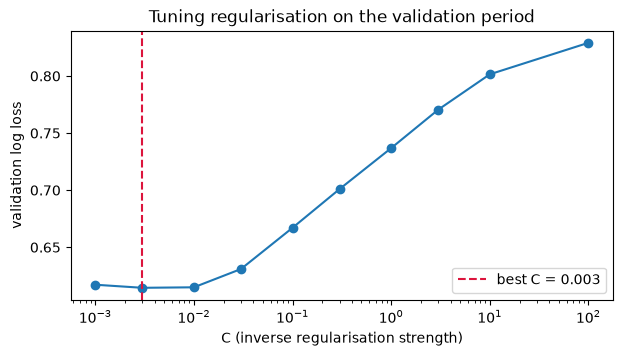

,val_log_loss
0.001,0.6172
0.003,0.6145
0.010,0.6149
0.030,0.6309
0.100,0.6671
0.300,0.7010
1.000,0.7369
3.000,0.7705
10.000,0.8015
100.000,0.8291


In [34]:
C_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]


def fit_sklearn(C):
    return LogisticRegression(C=C, tol=1e-10, max_iter=10_000).fit(X["train"], y["train"])


val_loss = pd.Series({C: log_loss(y["val"], fit_sklearn(C).predict_proba(X["val"])[:, 1]) for C in C_GRID})
BEST_C = val_loss.idxmin()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogx(val_loss.index, val_loss.values, marker="o")
ax.axvline(BEST_C, color="crimson", ls="--", label=f"best C = {BEST_C}")
ax.set_xlabel("C (inverse regularisation strength)")
ax.set_ylabel("validation log loss")
ax.set_title("Tuning regularisation on the validation period")
ax.legend()
save_fig(fig, "tuning_C")

sk_model = fit_sklearn(BEST_C)
val_loss.round(4).to_frame("val_log_loss")

In [35]:
LAMBDA = 1 / (2 * BEST_C * len(y["train"]))
EPOCHS = 3000
LR_GRID = [0.01, 0.1, 0.5, 1.0]

Xt = {s: torch.tensor(X[s], dtype=torch.float32) for s in SPLITS}
yt = {s: torch.tensor(y[s], dtype=torch.float32) for s in SPLITS}
n_features = Xt["train"].shape[1]


def pick_lr(histories, tol=1e-6):
    """Fastest learning rate whose run reaches the best final objective; diverging runs drop out."""
    best = min(h[-1] for h in histories.values())
    epochs_needed = {lr: next((i for i, v in enumerate(h) if v - best < tol), None) for lr, h in histories.items()}
    print("epochs to converge per lr (None = never converged / diverged):", epochs_needed)
    converged = {lr: e for lr, e in epochs_needed.items() if e is not None}
    return min(converged, key=converged.get)


def bce_with_logits(z, target):
    # -[y log sigmoid(z) + (1-y) log(1 - sigmoid(z))], rewritten as softplus(z) - y*z,
    # which is the same quantity but doesn't overflow / take log(0) for large |z|.
    return (torch.nn.functional.softplus(z) - target * z).mean()


def train_manual(lr, epochs=EPOCHS):
    w = torch.zeros(n_features, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    history = []
    for _ in range(epochs):
        z = Xt["train"] @ w + b
        loss = bce_with_logits(z, yt["train"]) + LAMBDA * (w ** 2).sum()
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
        w.grad.zero_()
        b.grad.zero_()
        history.append(loss.item())
    return w.detach(), b.detach(), history


manual_runs = {lr: train_manual(lr) for lr in LR_GRID}
LR_MANUAL = pick_lr({lr: run[2] for lr, run in manual_runs.items()})
w_manual, b_manual, manual_history = manual_runs[LR_MANUAL]
print(f"chosen lr = {LR_MANUAL}, final training objective = {manual_history[-1]:.6f}")

epochs to converge per lr (None = never converged / diverged): {0.01: 2013, 0.1: 200, 0.5: 38, 1.0: None}
chosen lr = 0.5, final training objective = 0.654023


## 10. Model 3: standard `nn.Module` + `torch.optim`

In [36]:
class LogisticRegressionModel(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.linear = nn.Linear(n_features, 1)

    def forward(self, x):
        return self.linear(x).squeeze(-1)  # logits; sigmoid is applied inside the loss / at prediction


def train_module(lr, epochs=EPOCHS):
    torch.manual_seed(0)  # nn.Linear starts from random weights
    model = LogisticRegressionModel(n_features)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    history = []
    for _ in range(epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(Xt["train"]), yt["train"]) + LAMBDA * (model.linear.weight ** 2).sum()
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    return model, history


module_runs = {lr: train_module(lr) for lr in LR_GRID}
LR_MODULE = pick_lr({lr: run[1] for lr, run in module_runs.items()})
module_model, module_history = module_runs[LR_MODULE]
print(f"chosen lr = {LR_MODULE}, final training objective = {module_history[-1]:.6f}")

epochs to converge per lr (None = never converged / diverged): {0.01: 2149, 0.1: 213, 0.5: 41, 1.0: None}
chosen lr = 0.5, final training objective = 0.654023


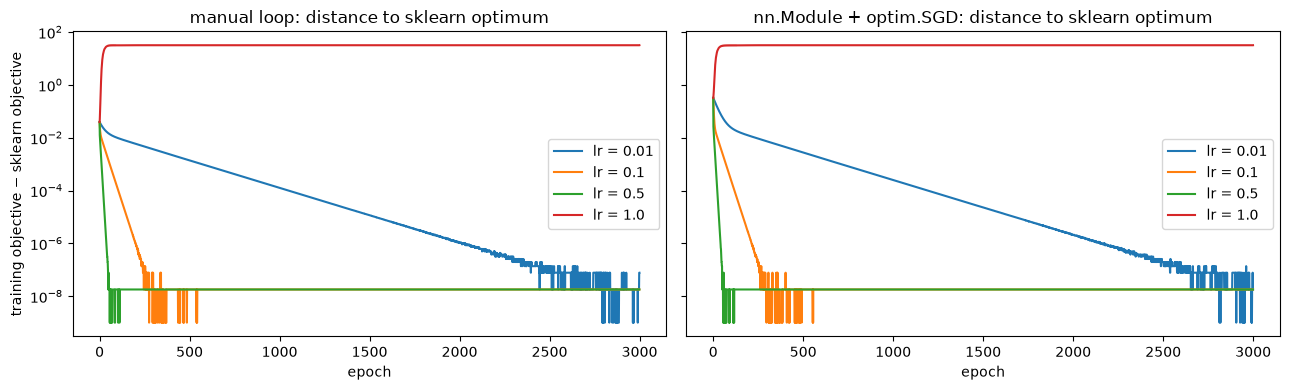

In [37]:
# Reference: sklearn's optimum expressed in the same units as the PyTorch objective.
sk_w = sk_model.coef_.ravel()
p_train_sk = sk_model.predict_proba(X["train"])[:, 1]
sk_objective = log_loss(y["train"], p_train_sk) + LAMBDA * (sk_w ** 2).sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, runs, title, get_hist in [
    (axes[0], manual_runs, "manual loop", lambda r: r[2]),
    (axes[1], module_runs, "nn.Module + optim.SGD", lambda r: r[1]),
]:
    for lr, run in runs.items():
        gap = np.array(get_hist(run)) - sk_objective
        ax.semilogy(np.maximum(gap, 1e-9), label=f"lr = {lr}")
    ax.set_title(f"{title}: distance to sklearn optimum")
    ax.set_xlabel("epoch")
    ax.legend()
axes[0].set_ylabel("training objective − sklearn objective")
fig.tight_layout()
save_fig(fig, "convergence")

## 11. Do the three implementations agree?

In [38]:
def proba_manual(Xs):
    with torch.no_grad():
        return torch.sigmoid(Xs @ w_manual + b_manual).numpy()


def proba_module(Xs):
    with torch.no_grad():
        return torch.sigmoid(module_model(Xs)).numpy()


proba = {
    "scikit-learn": {s: sk_model.predict_proba(X[s])[:, 1] for s in SPLITS},
    "manual PyTorch": {s: proba_manual(Xt[s]) for s in SPLITS},
    "nn.Module + optim": {s: proba_module(Xt[s]) for s in SPLITS},
}

coefs = pd.DataFrame({
    "scikit-learn": np.append(sk_model.intercept_, sk_w),
    "manual PyTorch": np.append(b_manual.numpy(), w_manual.numpy()),
    "nn.Module + optim": np.append(module_model.linear.bias.detach().numpy(),
                                   module_model.linear.weight.detach().numpy().ravel()),
}, index=["intercept"] + FEATURES)

for name in ["manual PyTorch", "nn.Module + optim"]:
    print(f"{name:18s} vs sklearn: max |coef diff| = {(coefs[name] - coefs['scikit-learn']).abs().max():.2e}, "
          f"max |test proba diff| = {np.abs(proba[name]['test'] - proba['scikit-learn']['test']).max():.2e}, "
          f"same test decisions: {np.mean((proba[name]['test'] >= THRESHOLD) == (proba['scikit-learn']['test'] >= THRESHOLD)):.0%}")
coefs.round(4)

manual PyTorch     vs sklearn: max |coef diff| = 1.07e-07, max |test proba diff| = 6.09e-08, same test decisions: 100%
nn.Module + optim  vs sklearn: max |coef diff| = 7.69e-08, max |test proba diff| = 5.59e-08, same test decisions: 100%


,scikit-learn,manual PyTorch,nn.Module + optim
intercept,-0.3596,-0.3596,-0.3596
ipca15,0.0814,0.0814,0.0814
ipca_12m,0.0375,0.0375,0.0375
usdbrl_chg_3m,0.0220,0.0220,0.0220
icbr_chg_3m,0.0947,0.0947,0.0947
real_rate_ex_post,-0.0485,-0.0485,-0.0485
ibcbr_growth_3m,-0.0066,-0.0066,-0.0066
tm_2,0.0087,0.0087,0.0087
tm_3,-0.0035,-0.0035,-0.0035
tm_4,0.0096,0.0096,0.0096


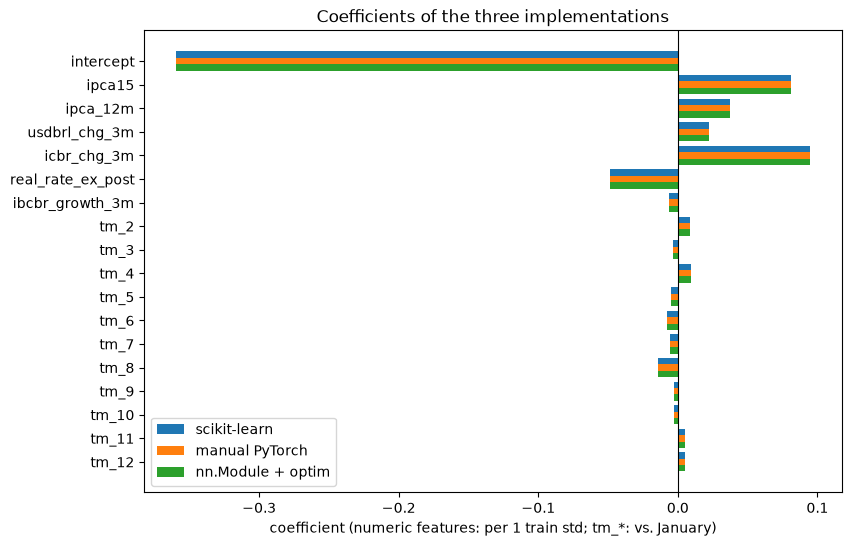

In [39]:
fig, ax = plt.subplots(figsize=(9, 6))
pos = np.arange(len(coefs))
for i, name in enumerate(coefs.columns):
    ax.barh(pos + (i - 1) * 0.27, coefs[name], height=0.27, label=name)
ax.set_yticks(pos, coefs.index)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("coefficient (numeric features: per 1 train std; tm_*: vs. January)")
ax.set_title("Coefficients of the three implementations")
ax.legend()
save_fig(fig, "coefficients")

## 12. Results vs. the persistence baseline

Every decision metric uses the cost-based threshold. **Validation** was used to choose C, so
**test** (2021 onwards, never touched during modelling) is the honest estimate.

In [40]:
rows = {}
for s in ["val", "test"]:
    rows[(s, "persistence (baseline)")] = evaluate(y[s], pred=baseline_pred[s])
    for name in proba:
        rows[(s, name)] = evaluate(y[s], proba=proba[name][s])
results = pd.DataFrame(rows).T
results.index.names = ["split", "model"]
results.to_csv(ARTIFACTS / "metrics.csv")
results.loc["test"].round(3)

,log_loss,roc_auc,recall,precision,missed_spikes,false_alarms,business_cost
model,,,,,,,
persistence (baseline),NaN,NaN,0.688,0.688,10.0,10.0,40.0
scikit-learn,0.651,0.745,1.000,0.471,0.0,36.0,36.0
manual PyTorch,0.651,0.745,1.000,0.471,0.0,36.0,36.0
nn.Module + optim,0.651,0.745,1.000,0.471,0.0,36.0,36.0


In [41]:
results.loc["val"].round(3)

,log_loss,roc_auc,recall,precision,missed_spikes,false_alarms,business_cost
model,,,,,,,
persistence (baseline),NaN,NaN,0.222,0.25,7.0,6.0,27.0
scikit-learn,0.614,0.626,1.000,0.25,0.0,27.0,27.0
manual PyTorch,0.614,0.626,1.000,0.25,0.0,27.0,27.0
nn.Module + optim,0.614,0.626,1.000,0.25,0.0,27.0,27.0


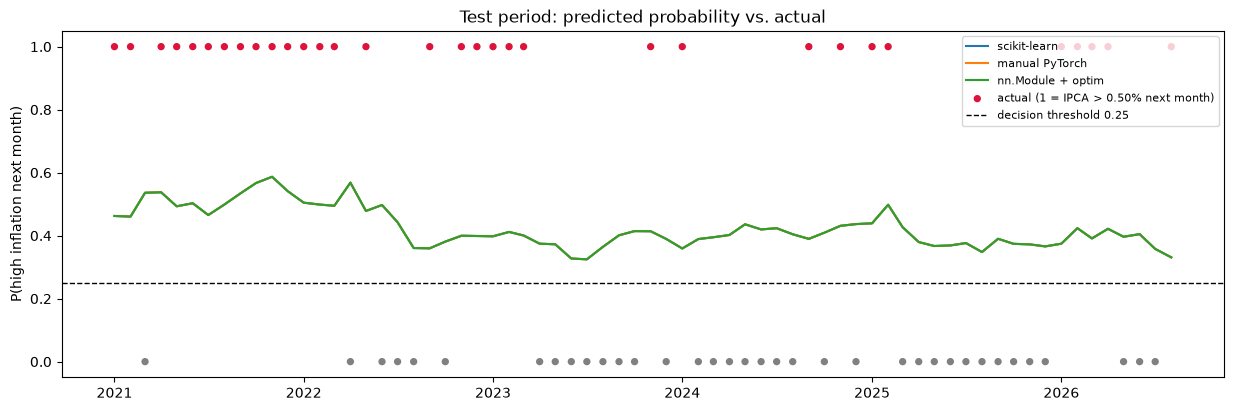

In [42]:
test_idx = parts["test"].index
fig, ax = plt.subplots(figsize=(15, 4.5))
for name in proba:
    ax.plot(test_idx, proba[name]["test"], lw=1.5, label=name)
ax.scatter(test_idx, y["test"], c=np.where(y["test"] == 1, "crimson", "grey"), s=18, zorder=3,
           label="actual (1 = IPCA > 0.50% next month)")
ax.axhline(THRESHOLD, color="black", ls="--", lw=1, label=f"decision threshold {THRESHOLD:.2f}")
ax.set_ylabel("P(high inflation next month)")
ax.set_title("Test period: predicted probability vs. actual")
ax.legend(loc="upper right", fontsize=8)
save_fig(fig, "test_predictions")

## 13. Save artifacts for the dashboard

The app loads these files and never retrains:
- `scaler.joblib`: the train-fitted scaler
- `sklearn_logreg.joblib`: Model 1
- `torch_manual.pt`: Model 2's `w` and `b`
- `torch_module.pt`: Model 3's `state_dict` (the app redefines `LogisticRegressionModel`)
- `config.json`: feature order, threshold, costs and chosen hyperparameters
- `features.csv` (saved earlier) and `metrics.csv`: the data and results tables

In [43]:
joblib.dump(scaler, MODEL_DIR / "scaler.joblib")
joblib.dump(sk_model, MODEL_DIR / "sklearn_logreg.joblib")
torch.save({"w": w_manual, "b": b_manual}, MODEL_DIR / "torch_manual.pt")
torch.save(module_model.state_dict(), MODEL_DIR / "torch_module.pt")

config = {
    "numeric_features": NUMERIC,
    "seasonal_features": SEASONAL,
    "threshold": THRESHOLD,
    "cost_fp": COST_FP,
    "cost_fn": COST_FN,
    "high_inflation_threshold_pct": THRESH,
    "C": float(BEST_C),
    "lambda": LAMBDA,
    "lr_manual": LR_MANUAL,
    "lr_module": LR_MODULE,
    "epochs": EPOCHS,
    "splits": {"train_end": TRAIN_END, "val_end": VAL_END},
}
(MODEL_DIR / "config.json").write_text(json.dumps(config, indent=2))
print("Saved:", sorted(p.name for p in MODEL_DIR.iterdir()))

Saved: ['config.json', 'scaler.joblib', 'sklearn_logreg.joblib', 'torch_manual.pt', 'torch_module.pt']
